# PMSGD without SMOTE (PIDD only): GA and PSO feature selection vs the paper
Re-implementation of Azad et al., *Multimedia Systems* (2021) on the Pima Indians Diabetes Database, **without SMOTE**.

| Variant | Feature selection |
|---|---|
| **PIDD** | none, all 8 features (baseline) |
| **PIDD+GA** | CFS merit searched by a genetic algorithm (the paper's method) |
| **PIDD+PSO** | CFS merit searched by binary particle swarm optimization |

GA and PSO share the same fitness, the same budget (20 × 50 = 1,000 evaluations), the same C4.5 tree, splits and seeds, so differences come from the optimizer alone. Two protocols are run: `paper` (fit on all data, then split) and `strict` (split first). Run all cells top to bottom (about 5 s); `data/diabetes.csv` must sit next to the notebook.

## 0. Imports and configuration
Settings from the paper: train fractions 60–80%, 10 repeats per split, GA parameters from Table 5. PSO uses the same swarm size and iterations as the GA. `PAPER_*` constants hold the paper's published results (Tables 6–11) used in the comparison.

In [1]:
%matplotlib inline
import os
import sys
import warnings
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore")  # KBinsDiscretizer warns when tied quantiles merge bins

DATA = "data/diabetes.csv"
OUT = "results"
os.makedirs(OUT, exist_ok=True)   # create the output folder next to the notebook if it is missing
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
# In PIDD a 0 in these columns is physiologically impossible -> it encodes "missing".
ZERO_IS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

SPLITS = [0.60, 0.65, 0.70, 0.75, 0.80]   # train fractions from the paper (60-40 ... 80-20)
N_RUNS = 10                               # the paper repeats every split 10 times
GA_PARAMS = dict(pc=0.6, pm=0.03, pop=20, gens=50)    # paper Table 5, column "PIDD + GA"
# PSO settings: same swarm size and iterations as the GA => same 1000 fitness evaluations.
# w, c1, c2 are the common constriction-style defaults (Clerc & Kennedy); vmax=4 is the usual
# velocity clamp for binary PSO (keeps the sigmoid away from 0/1 saturation).
PSO_PARAMS = dict(n_particles=20, iters=50, w=0.7, c1=1.5, c2=1.5, vmax=4.0)
VARIANTS = ["PIDD", "PIDD+GA", "PIDD+PSO"]
METRICS = ["CA", "CE", "Precision", "Sensitivity", "FM", "AUROC"]

# Paper results for the variants it reports without SMOTE (its Tables 6-10 top-5 CA of 10 runs per
# split, and Table 11 best outcome). The paper has no PSO variant.
PAPER_TOP5_CA = {
    "PIDD": {"60-40": [76.6234, 75.9740, 75.3247, 75.2443, 74.5928],
             "65-35": [79.5539, 75.4647, 75.4647, 75.0929, 73.6059],
             "70-30": [77.0563, 77.0563, 75.3247, 74.8918, 73.5931],
             "75-25": [77.6042, 76.5625, 76.5625, 76.5625, 74.4792],
             "80-20": [77.2727, 77.2727, 75.1634, 74.6753, 74.0260]},
    "PIDD+GA": {"60-40": [76.9481, 76.2215, 75.9740, 75.5700, 75.3247],
                "65-35": [79.5539, 75.8364, 75.4647, 75.4647, 75.0929],
                "70-30": [77.9221, 76.5217, 75.3247, 74.8918, 74.8918],
                "75-25": [77.6042, 77.6042, 77.0833, 76.5625, 76.5625],
                "80-20": [77.9221, 76.6234, 75.9740, 75.3247, 75.1634]}}

# Paper, best run per split (Tables 6-10, first row of each block): CA, precision, sensitivity, F-measure, AUROC.
PAPER_BEST_BY_SPLIT = {
    "PIDD": {"60-40": (76.6234, .7500, .5000, .6000, .7754), "65-35": (79.5539, .7910, .5638, .6584, .7619),
             "70-30": (77.0563, .6458, .7654, .7006, .7865), "75-25": (77.6042, .7143, .5970, .6504, .7427),
             "80-20": (77.2727, .8065, .4630, .5882, .8129)},
    "PIDD+GA": {"60-40": (76.9481, .6609, .7037, .6816, .8036), "65-35": (79.5539, .7910, .5638, .6584, .7632),
                "70-30": (77.9221, .7419, .5679, .6434, .7776), "75-25": (77.6042, .7143, .5970, .6504, .7427),
                "80-20": (77.9221, .7273, .5926, .6531, .8222)}}
PAPER_BEST = {"PIDD": [79.5539, 20.4461, 0.7910, 0.5638, 0.6584, 0.7619],
              "PIDD+GA": [79.5539, 20.4461, 0.7910, 0.5638, 0.6584, 0.7632]}

## 1. Pre-processing layer (no SMOTE)
* `fit_preprocess` learns the column medians and Tukey outlier fences (Q1 − 1.5·IQR, Q3 + 1.5·IQR) and returns them in a dict, so the same values can be applied to unseen test data.
* `apply_preprocess` treats a 0 in Glucose, BloodPressure, SkinThickness, Insulin and BMI as missing (physiologically impossible), fills it with the stored median and clips outliers. The paper names no outlier method, so IQR clipping is my choice.

In [2]:
def fit_preprocess(X: pd.DataFrame) -> dict:
    """Learn imputation values (medians) and outlier fences (Tukey: Q1-1.5*IQR, Q3+1.5*IQR).

    Returned as a dict so the SAME parameters can later be applied to unseen test data.
    """
    X = X.copy()
    X[ZERO_IS_MISSING] = X[ZERO_IS_MISSING].replace(0, np.nan)  # 0 == missing
    median = X.median()                                         # median ignores NaN
    X = X.fillna(median)
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    return dict(median=median, lo=q1 - 1.5 * iqr, hi=q3 + 1.5 * iqr)


def apply_preprocess(X: pd.DataFrame, p: dict) -> pd.DataFrame:
    """Impute missing values with the stored medians, then clip (winsorise) outliers."""
    X = X.copy()
    X[ZERO_IS_MISSING] = X[ZERO_IS_MISSING].replace(0, np.nan)
    return X.fillna(p["median"]).clip(lower=p["lo"], upper=p["hi"], axis=1)

## 2. Dimensionality reduction: CFS merit as fitness, GA or PSO as the search
* `symmetrical_uncertainty` / `correlation_tables`: information gain normalised to [0, 1] (paper Eqs. 3–6), computed once for feature–class (`r_cf`) and feature–feature (`r_ff`) pairs after 10-bin equal-frequency discretisation.
* `cfs_merit` (paper Eq. 2): `A = m·r_cf / √(m + m(m−1)·r_ff)`; an empty subset scores 0.
* `ga_select`: binary chromosomes, roulette-wheel selection, one-point crossover, bit-flip mutation, plus elitism (my addition).
* `pso_select`: binary PSO. Each particle is a feature subset with a velocity per bit; `v ← w·v + c1·r1·(pbest − x) + c2·r2·(gbest − x)`, clipped to ±vmax, then the bit becomes 1 with probability `sigmoid(v)`.
* `exhaustive_best`: brute force over all 255 subsets, to check both optimizers and measure gaps.

In [3]:
def _entropy(codes):
    """Shannon entropy H (bits) of a vector of non-negative integer codes (paper Eq. 3)."""
    p = np.bincount(codes) / len(codes)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()


def symmetrical_uncertainty(a, b):
    """UCD = 2 * (H(a) + H(b) - H(a,b)) / (H(a) + H(b))  -> information gain normalised to [0,1]
    (paper Eqs. 5-6; H(a)+H(b)-H(a,b) equals H(C) - H(C|D))."""
    ha, hb = _entropy(a), _entropy(b)
    if ha + hb == 0:
        return 0.0
    hab = _entropy(a * (b.max() + 1) + b)          # joint entropy via combined code
    return 2 * (ha + hb - hab) / (ha + hb)


def correlation_tables(X, y, n_bins=10):
    """Pre-compute feature-class (r_cf) and feature-feature (r_ff) correlations once, so the
    optimizer's fitness is cheap. Continuous features are first discretised into 10 equal-frequency
    bins (Weka's CFS uses MDL discretisation; this is a simpler stand-in)."""
    D = KBinsDiscretizer(n_bins, encode="ordinal", strategy="quantile").fit_transform(X).astype(int)
    y = np.asarray(y).astype(int)
    n = D.shape[1]
    r_cf = np.array([symmetrical_uncertainty(D[:, j], y) for j in range(n)])
    r_ff = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            r_ff[i, j] = r_ff[j, i] = symmetrical_uncertainty(D[:, i], D[:, j])
    return r_cf, r_ff


def cfs_merit(mask, r_cf, r_ff):
    """Paper Eq. 2:  A_s = m * MCD_al / sqrt(m + m(m-1) * MCD_aa).
    High when features correlate with the class (MCD_al) and little with each other (MCD_aa).
    An empty subset scores 0, so both optimizers are pushed away from it."""
    idx = np.flatnonzero(mask)
    m = len(idx)
    if m == 0:
        return 0.0
    mcd_al = r_cf[idx].mean()
    mcd_aa = 0.0 if m == 1 else r_ff[np.ix_(idx, idx)].sum() / (m * (m - 1))  # diag is 0
    return m * mcd_al / np.sqrt(m + m * (m - 1) * mcd_aa)


def ga_select(r_cf, r_ff, pc, pm, pop, gens, seed=0, trace=None):
    """Genetic algorithm (the paper's optimizer): binary chromosomes (bit j = 1 -> feature j kept),
    roulette-wheel selection, one-point crossover, bit-flip mutation, plus elitism.
    Returns (best_mask, best_merit, per-generation best merit)."""
    rng = np.random.default_rng(seed)
    n = len(r_cf)
    P = rng.random((pop, n)) < 0.5
    best, best_f, history = None, -1.0, []
    for _ in range(gens):
        f = np.array([cfs_merit(c, r_cf, r_ff) for c in P])
        if f.max() > best_f:
            best, best_f = P[f.argmax()].copy(), f.max()
        history.append(best_f)
        if trace is not None:
            trace.append(best.copy())                                   # for the live demo only
        probs = f / f.sum() if f.sum() > 0 else np.full(pop, 1 / pop)
        parents = P[rng.choice(pop, pop, p=probs)]                       # roulette wheel
        kids = parents.copy()
        for a in range(0, pop - 1, 2):                                   # one-point crossover
            if rng.random() < pc:
                cut = rng.integers(1, n)
                kids[a, cut:], kids[a + 1, cut:] = parents[a + 1, cut:].copy(), parents[a, cut:].copy()
        kids ^= rng.random(kids.shape) < pm                              # bit mutation
        kids[0] = best                                                   # elitism
        P = kids
    return best, best_f, history


def pso_select(r_cf, r_ff, n_particles, iters, w, c1, c2, vmax, seed=0, trace=None):
    """NEW: binary particle swarm optimization (Kennedy & Eberhart, 1997) for feature selection.

    Every particle is a candidate feature subset (a binary mask, bit j = 1 -> feature j kept) that
    also carries a real-valued VELOCITY per bit. In each iteration, for every particle and bit:
        v <- w*v + c1*r1*(pbest - x) + c2*r2*(gbest - x)     # inertia + pull to own best + pull to swarm best
        v <- clip(v, -vmax, vmax)                            # stop the velocity from exploding
        x <- 1 with probability sigmoid(v), else 0           # velocity becomes the chance of keeping the feature
    pbest is each particle's best position so far and gbest the best position of the whole swarm;
    r1, r2 are fresh U(0,1) numbers. Fitness is the same CFS merit the GA uses.
    Returns (best_mask, best_merit, per-iteration best merit)."""
    rng = np.random.default_rng(seed)
    n = len(r_cf)
    X = rng.random((n_particles, n)) < 0.5                    # positions: random subsets
    V = rng.uniform(-vmax, vmax, (n_particles, n))            # velocities
    fit = np.array([cfs_merit(x, r_cf, r_ff) for x in X])
    pbest, pbest_f = X.copy(), fit.copy()                     # personal bests
    g = pbest_f.argmax()
    gbest, gbest_f = pbest[g].copy(), pbest_f[g]              # global best
    history = [gbest_f]                                       # iteration 1 = the initial swarm
    if trace is not None:
        trace.append(gbest.copy())                            # for the live demo only
    for _ in range(iters - 1):
        r1, r2 = rng.random(V.shape), rng.random(V.shape)
        Xf = X.astype(float)                                         # 0/1 so the differences are numeric
        V = w * V + c1 * r1 * (pbest - Xf) + c2 * r2 * (gbest - Xf)
        V = np.clip(V, -vmax, vmax)
        X = rng.random(V.shape) < 1.0 / (1.0 + np.exp(-V))           # sigmoid transfer + sampling
        fit = np.array([cfs_merit(x, r_cf, r_ff) for x in X])
        better = fit > pbest_f                                       # update personal bests
        pbest[better], pbest_f[better] = X[better], fit[better]
        g = pbest_f.argmax()
        if pbest_f[g] > gbest_f:                                     # update global best
            gbest, gbest_f = pbest[g].copy(), pbest_f[g]
        history.append(gbest_f)
        if trace is not None:
            trace.append(gbest.copy())
    return gbest, gbest_f, history


def exhaustive_best(r_cf, r_ff):
    """Brute force over all 2^n - 1 subsets (n=8 -> 255). Used to sanity-check both optimizers."""
    n = len(r_cf)
    masks = [np.array([(s >> j) & 1 for j in range(n)], bool) for s in range(1, 2 ** n)]
    return max(masks, key=lambda m: cfs_merit(m, r_cf, r_ff))

## 3. Training layer: C4.5 decision tree
Written from scratch because scikit-learn has no gain-ratio tree: binary threshold splits on numeric features, MDL penalty, attribute chosen by gain ratio among those with at least the average gain, at least 2 instances per leaf, bottom-up pessimistic-error pruning at CF 0.25 (J48 defaults). Not implemented: subtree raising.

In [4]:
def _h(p):
    """Binary entropy of probability array p."""
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


class C45:
    """C4.5 / Weka-J48 style tree.
      * binary threshold split on numeric features, threshold chosen by information gain
        (minus the MDL penalty log2(#thresholds)/N for numeric attributes, as in C4.5 rel. 8)
      * attribute chosen by GAIN RATIO among attributes whose gain is >= the average gain
      * min 2 instances per leaf (J48 default), bottom-up pessimistic-error pruning, CF = 0.25
    Not implemented: subtree raising (J48's second pruning move) and missing-value handling
    (data are already imputed)."""

    def __init__(self, min_leaf=2, cf=0.25):
        self.min_leaf, self.cf = min_leaf, cf
        self.z = NormalDist().inv_cdf(1 - cf)       # 0.6745 for CF = 0.25

    # ---- growing --------------------------------------------------------
    def _best_split(self, X, y):
        n, pos = len(y), y.sum()
        base = _h(np.array(pos / n))
        cands = []                                              # (gain, gain_ratio, feature, threshold)
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="stable")
            xs, ys = X[order, j], y[order]
            nl = np.arange(1, n)                                # left size for each cut position
            cl = np.cumsum(ys)[:-1]                             # positives on the left
            distinct = xs[1:] > xs[:-1]                         # can only cut between different values
            valid = distinct & (nl >= self.min_leaf) & (n - nl >= self.min_leaf)
            if not valid.any():
                continue
            gain = base - (nl / n * _h(cl / nl) + (n - nl) / n * _h((pos - cl) / (n - nl)))
            gain = np.where(valid, gain, -np.inf)
            k = gain.argmax()
            g = gain[k] - np.log2(max(distinct.sum(), 1)) / n   # MDL penalty
            if g <= 0:
                continue
            w = nl[k] / n
            split_info = -(w * np.log2(w) + (1 - w) * np.log2(1 - w))
            cands.append((g, g / split_info, j, (xs[k] + xs[k + 1]) / 2))
        if not cands:
            return None
        avg = np.mean([c[0] for c in cands])
        return max((c for c in cands if c[0] >= avg - 1e-12), key=lambda c: c[1])

    def _grow(self, X, y):
        node = dict(n=len(y), pos=int(y.sum()), leaf=True)
        if node["pos"] in (0, node["n"]) or node["n"] < 2 * self.min_leaf:
            return node
        s = self._best_split(X, y)
        if s is None:
            return node
        _, _, j, thr = s
        left = X[:, j] <= thr
        node.update(leaf=False, feat=j, thr=thr,
                    left=self._grow(X[left], y[left]), right=self._grow(X[~left], y[~left]))
        return node

    # ---- pruning --------------------------------------------------------
    def _upper_error(self, n, e):
        """Pessimistic (upper confidence limit) number of errors for a leaf with n cases, e errors."""
        if e == 0:
            return n * (1 - self.cf ** (1 / n))
        f, z = e / n, self.z
        r = (f + z * z / (2 * n) + z * np.sqrt(f / n - f * f / n + z * z / (4 * n * n))) / (1 + z * z / n)
        return r * n

    def _prune(self, node):
        """Bottom-up: collapse a subtree into a leaf if the leaf's estimated error is not worse."""
        leaf_err = self._upper_error(node["n"], min(node["pos"], node["n"] - node["pos"]))
        if node["leaf"]:
            return leaf_err
        sub_err = self._prune(node["left"]) + self._prune(node["right"])
        if leaf_err <= sub_err + 0.1:
            node.update(leaf=True)
            node.pop("left"), node.pop("right")
            return leaf_err
        return sub_err

    # ---- public API -----------------------------------------------------
    def fit(self, X, y):
        self.root = self._grow(np.asarray(X, float), np.asarray(y).astype(int))
        self._prune(self.root)
        return self

    def predict_proba(self, X):
        """P(diabetes) = fraction of positives in the leaf the sample falls into."""
        X = np.asarray(X, float)
        out = np.empty(len(X))

        def walk(node, rows):
            if node["leaf"]:
                out[rows] = node["pos"] / node["n"]
                return
            go_left = X[rows, node["feat"]] <= node["thr"]
            walk(node["left"], rows[go_left])
            walk(node["right"], rows[~go_left])

        walk(self.root, np.arange(len(X)))
        return out

    def n_leaves(self, node=None):
        node = node or self.root
        return 1 if node["leaf"] else self.n_leaves(node["left"]) + self.n_leaves(node["right"])

## 4. Evaluation layer
CA and CE in %, precision, sensitivity, F-measure, AUROC and the confusion matrix, with diabetic as the positive class.

In [5]:
def evaluate(y_true, proba):
    """CA/CE in %, others in [0,1]; 'positive' = diabetic (class 1). Also returns the confusion matrix."""
    pred = (proba > 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    ca = accuracy_score(y_true, pred) * 100
    return dict(CA=ca, CE=100 - ca,
                Precision=precision_score(y_true, pred, zero_division=0),
                Sensitivity=recall_score(y_true, pred, zero_division=0),
                FM=f1_score(y_true, pred, zero_division=0),
                AUROC=roc_auc_score(y_true, proba),
                TP=tp, FP=fp, TN=tn, FN=fn)

## 5. Experiment protocols
* `paper`: pre-processing and feature selection fitted on the whole dataset, then a random split (as in the paper).
* `strict`: split first (stratified), then medians, fences, GA and PSO see only the training part.
* `run_experiment`: 3 variants × 5 splits × 10 repeats × 2 protocols. `convergence_study` compares GA and PSO over 100 seeds; `strict_optimum_check` compares both with the true optimum on each strict training part.

In [6]:
def select_features(X, y, seed):
    """Run both optimizers on the same CFS tables (same data, same seed, same evaluation budget)."""
    r_cf, r_ff = correlation_tables(X, y)
    return (ga_select(r_cf, r_ff, seed=seed, **GA_PARAMS),
            pso_select(r_cf, r_ff, seed=seed, **PSO_PARAMS))


def make_variants(Xtr, ytr, Xte, yte, ga, pso):
    full = np.ones(Xtr.shape[1], bool)
    return {"PIDD": (Xtr, ytr, Xte, yte, full),
            "PIDD+GA": (Xtr, ytr, Xte, yte, ga[0]),
            "PIDD+PSO": (Xtr, ytr, Xte, yte, pso[0])}


def paper_global(raw_X, y):
    """Paper protocol, done ONCE: pre-process + GA + PSO on the whole dataset."""
    X = apply_preprocess(raw_X, fit_preprocess(raw_X)).to_numpy()
    ga, pso = select_features(X, y, seed=0)
    return X, ga, pso


def paper_split(X, y, ga, pso, frac, seed):
    """Random (non-stratified, like Weka's percentage split) train/test split of the processed data."""
    Xtr, Xte, ytr, yte = train_test_split(X, y, train_size=frac, random_state=seed)
    return make_variants(Xtr, ytr, Xte, yte, ga, pso)


def strict_split(raw_X, y, frac, seed):
    """Leak-free protocol: split first; medians, fences, GA and PSO see only the training part."""
    Xtr, Xte, ytr, yte = train_test_split(raw_X, y, train_size=frac, random_state=seed, stratify=y)
    prep = fit_preprocess(Xtr)
    Xtr, Xte = apply_preprocess(Xtr, prep).to_numpy(), apply_preprocess(Xte, prep).to_numpy()
    ytr, yte = np.asarray(ytr), np.asarray(yte)
    ga, pso = select_features(Xtr, ytr, seed)
    return make_variants(Xtr, ytr, Xte, yte, ga, pso)


def run_experiment(raw_X, y):
    """Per run: split -> (GA, PSO) -> train C4.5 -> evaluate. 2 protocols x 5 splits x 10 runs x 3 variants."""
    rows = []
    g_X, g_ga, g_pso = paper_global(raw_X, y)
    for protocol in ("paper", "strict"):
        for frac in SPLITS:
            for run in range(N_RUNS):
                data = (paper_split(g_X, y, g_ga, g_pso, frac, run) if protocol == "paper"
                        else strict_split(raw_X, y, frac, run))
                for v in VARIANTS:
                    Xtr, ytr, Xte, yte, mask = data[v]
                    tree = C45().fit(Xtr[:, mask], ytr)
                    rows.append(dict(protocol=protocol, split=f"{int(frac*100)}-{int(100-frac*100)}",
                                     run=run, variant=v, leaves=tree.n_leaves(),
                                     features="".join(map(str, mask.astype(int))),
                                     **evaluate(yte, tree.predict_proba(Xte[:, mask]))))
    return pd.DataFrame(rows), g_ga, g_pso


def convergence_study(X, y, n_seeds=100):
    """Optimizer-only comparison on the whole processed data: 100 independent runs of GA and PSO.
    Records how often each reaches the global optimum (known by brute force) and after how many
    generations/iterations (each = 20 fitness evaluations)."""
    r_cf, r_ff = correlation_tables(X, y)
    opt = cfs_merit(exhaustive_best(r_cf, r_ff), r_cf, r_ff)
    out = {}
    for name, fn, params in (("GA", ga_select, GA_PARAMS), ("PSO", pso_select, PSO_PARAMS)):
        hists = np.array([fn(r_cf, r_ff, seed=s, **params)[2] for s in range(n_seeds)])
        hit = hists >= opt - 1e-9
        first = np.where(hit.any(axis=1), hit.argmax(axis=1) + 1, np.nan)   # 1-based generation
        out[name] = dict(optimum=opt, success=float(hit[:, -1].mean()), first=first,
                         final=hists[:, -1].mean(), curve=hists.mean(axis=0))
    return out


def strict_optimum_check(raw_X, y):
    """On each of the 50 strict training parts, compare the merit found by GA and PSO with the true
    optimum (brute force). Returns how many of the 50 searches missed the optimum."""
    miss = {"GA": 0, "PSO": 0, "runs": 0}
    for frac in SPLITS:
        for seed in range(N_RUNS):
            Xtr, _, ytr, _ = train_test_split(raw_X, y, train_size=frac, random_state=seed, stratify=y)
            Xt = apply_preprocess(Xtr, fit_preprocess(Xtr)).to_numpy()
            r_cf, r_ff = correlation_tables(Xt, ytr)
            opt = cfs_merit(exhaustive_best(r_cf, r_ff), r_cf, r_ff)
            miss["GA"] += ga_select(r_cf, r_ff, seed=seed, **GA_PARAMS)[1] < opt - 1e-9
            miss["PSO"] += pso_select(r_cf, r_ff, seed=seed, **PSO_PARAMS)[1] < opt - 1e-9
            miss["runs"] += 1
    return miss

## 6. Reporting
Builds every table (mean ± std, paired tests, confusion matrices, selected features, optimizer comparison) and `paper_comparison`, the tables that compare this experiment with the paper's reported performance (its best runs per split, its Table 11, and the best-5-of-10 averages).

In [7]:
def names(bits):
    return ", ".join(f for f, b in zip(FEATURES, bits) if b == "1")


def bits_of(mask):
    return "".join(map(str, mask.astype(int)))


def top5_mean(s):
    """The paper reports the best 5 of 10 runs per split; this is the mean CA of those 5."""
    return s.sort_values(ascending=False).head(5).mean()


def paper_comparison(df, splits):
    """Markdown tables comparing the paper's reported performance with this experiment.
    Paper numbers are its best run per split (it reports the best 5 of 10 runs only), so ours are shown
    the same way (best run per split) and also as the average over ALL runs, which the paper never reports."""
    md = ["\n## Comparison: paper vs this experiment\n"]
    cols = ["CA %", "Precision", "Sensitivity", "F-measure", "AUROC"]
    keys = ["CA", "Precision", "Sensitivity", "FM", "AUROC"]
    for v in ("PIDD", "PIDD+GA"):
        md.append(f"\n### {v}: best run per split, paper vs ours\n")
        md.append("| Split | Source | " + " | ".join(cols) + " |")
        md.append("|---|---|" + "---|" * len(cols))
        for sp in splits:
            md.append(f"| {sp} | Paper | " + " | ".join(
                f"{x:.2f}" if i == 0 else f"{x:.3f}" for i, x in enumerate(PAPER_BEST_BY_SPLIT[v][sp])) + " |")
            for protocol in ("strict", "paper"):
                d = df[(df.protocol == protocol) & (df.variant == v) & (df.split == sp)]
                b = d.sort_values("CA", ascending=False).iloc[0]
                md.append(f"| {sp} | Ours, `{protocol}` | " + " | ".join(
                    f"{b[k]:.2f}" if k == "CA" else f"{b[k]:.3f}" for k in keys) + " |")
    md.append("\n### Summary: paper vs ours (accuracy %, mean of the best 5 runs per split, averaged over the 5 splits)\n")
    md.append("| Variant | Paper | Ours, `strict` | Ours, `paper` | Ours, `strict` (all 50 runs) | Ours, `paper` (all 50 runs) |")
    md.append("|---|---|---|---|---|---|")
    for v in VARIANTS:
        pap = f"{np.mean([np.mean(PAPER_TOP5_CA[v][s]) for s in splits]):.2f}" if v in PAPER_TOP5_CA else "not in paper"
        cells = []
        for protocol in ("strict", "paper"):
            d = df[(df.protocol == protocol) & (df.variant == v)]
            cells.append((np.mean([top5_mean(d[d.split == s].CA) for s in splits]), d.CA.mean()))
        md.append(f"| {v} | {pap} | {cells[0][0]:.2f} | {cells[1][0]:.2f} | {cells[0][1]:.2f} | {cells[1][1]:.2f} |")
    md.append("\n### Paper's best outcome (its Table 11) vs ours\n")
    md.append("| Variant | Source | " + " | ".join(METRICS) + " |")
    md.append("|---|---|" + "---|" * len(METRICS))
    for v in VARIANTS:
        if v in PAPER_BEST:
            md.append(f"| {v} | Paper | " + " | ".join(
                f"{x:.2f}" if mm in ("CA", "CE") else f"{x:.4f}" for mm, x in zip(METRICS, PAPER_BEST[v])) + " |")
        for protocol in ("strict", "paper"):
            b = df[(df.protocol == protocol) & (df.variant == v)].sort_values("CA", ascending=False).iloc[0]
            md.append(f"| {v} | Ours, `{protocol}` ({b['split']}) | " + " | ".join(
                f"{b[mm]:.2f}" if mm in ("CA", "CE") else f"{b[mm]:.4f}" for mm in METRICS) + " |")
    return md


def report(df, g_ga, g_pso, conv, miss):
    md = []
    splits = [f"{int(f*100)}-{int(100-f*100)}" for f in SPLITS]
    sub = lambda p, v: df[(df.protocol == p) & (df.variant == v)]

    for protocol in ("paper", "strict"):
        md.append(f"\n### Protocol `{protocol}`: mean ± std over {len(SPLITS)*N_RUNS} runs "
                  f"({len(SPLITS)} splits x {N_RUNS} repeats)\n")
        md.append("| Dataset | " + " | ".join(METRICS) + " | Leaves |")
        md.append("|---|" + "---|" * (len(METRICS) + 1))
        for v in VARIANTS:
            s = sub(protocol, v)
            md.append(f"| {v} | " + " | ".join(
                f"{s[m].mean():.2f} ± {s[m].std():.2f}" if m in ("CA", "CE")
                else f"{s[m].mean():.3f} ± {s[m].std():.3f}" for m in METRICS)
                + f" | {s.leaves.mean():.1f} |")
        md.append(f"\n### Protocol `{protocol}`: mean CA (%) per split\n")
        md.append(df[df.protocol == protocol].pivot_table(index="variant", columns="split", values="CA",
                  aggfunc="mean").loc[VARIANTS, splits].round(2).to_markdown())

    md.append("\n### Mean CA of the top-5 runs (of 10) per split: the paper's reporting rule\n")
    md.append("| Dataset | Source | " + " | ".join(splits) + " | Average |")
    md.append("|---|---|" + "---|" * (len(splits) + 1))
    for v in VARIANTS:
        if v in PAPER_TOP5_CA:
            paper = [np.mean(PAPER_TOP5_CA[v][s]) for s in splits]
            md.append(f"| {v} | Paper | " + " | ".join(f"{x:.2f}" for x in paper) + f" | {np.mean(paper):.2f} |")
        for protocol in ("paper", "strict"):
            d = sub(protocol, v)
            ours = [top5_mean(d[d.split == s].CA) for s in splits]
            md.append(f"| {v} | Ours, `{protocol}` | " + " | ".join(f"{x:.2f}" for x in ours)
                      + f" | {np.mean(ours):.2f} |")

    md.append("\n### Best single run per dataset\n")
    md.append("| Dataset | Source | Split | " + " | ".join(METRICS) + " |")
    md.append("|---|---|---|" + "---|" * len(METRICS))
    for v in VARIANTS:
        if v in PAPER_BEST:
            md.append(f"| {v} | Paper | best of 10 | " + " | ".join(
                f"{x:.2f}" if m in ("CA", "CE") else f"{x:.4f}" for m, x in zip(METRICS, PAPER_BEST[v])) + " |")
        for protocol in ("paper", "strict"):
            b = sub(protocol, v).sort_values("CA", ascending=False).iloc[0]
            md.append(f"| {v} | Ours, `{protocol}` | {b['split']} | " + " | ".join(
                f"{b[m]:.2f}" if m in ("CA", "CE") else f"{b[m]:.4f}" for m in METRICS) + " |")

    md.append("\n### Paired comparisons (same split, same seed): mean difference, paired t-test p, runs where the first is better\n")
    md.append("| Protocol | Comparison | Metric | Mean difference | p | Better in |")
    md.append("|---|---|---|---|---|---|")
    for protocol in ("paper", "strict"):
        for first, second in (("PIDD+GA", "PIDD"), ("PIDD+PSO", "PIDD"), ("PIDD+PSO", "PIDD+GA")):
            a = sub(protocol, first).sort_values(["split", "run"])
            b = sub(protocol, second).sort_values(["split", "run"])
            for m in ("CA", "Sensitivity", "AUROC"):
                diff = a[m].to_numpy() - b[m].to_numpy()
                p = ttest_rel(a[m], b[m]).pvalue if np.any(diff) else float("nan")
                md.append(f"| {protocol} | {first} − {second} | {m} | {diff.mean():+.3f} | {p:.3f} | "
                          f"{(diff > 0).sum()} / {len(diff)} |")

    md.append("\n### Confusion matrices summed over all 50 runs (positive = diabetic)\n")
    md.append("| Protocol | Dataset | TP | FN | FP | TN | Sensitivity | Specificity |")
    md.append("|---|---|---|---|---|---|---|---|")
    for protocol in ("paper", "strict"):
        for v in VARIANTS:
            s = sub(protocol, v)[["TP", "FN", "FP", "TN"]].sum()
            md.append(f"| {protocol} | {v} | {s.TP} | {s.FN} | {s.FP} | {s.TN} | "
                      f"{s.TP/(s.TP+s.FN):.3f} | {s.TN/(s.TN+s.FP):.3f} |")

    md.append("\n### Features selected\n")
    md.append(f"- whole-data GA (paper protocol): **{names(bits_of(g_ga[0]))}** (CFS merit {g_ga[1]:.4f}); "
              "the paper reports Glucose, BMI, DiabetesPedigreeFunction, Age")
    md.append(f"- whole-data PSO (paper protocol): **{names(bits_of(g_pso[0]))}** (CFS merit {g_pso[1]:.4f})")
    for v in ("PIDD+GA", "PIDD+PSO"):
        freq = sub("strict", v).features.value_counts()
        md.append(f"- strict protocol, {v}, subsets seen in {freq.sum()} runs:")
        for bits, c in freq.head(4).items():
            md.append(f"    - {c}x: {names(bits)}")

    md.append("\n### Optimizer comparison: 100 independent runs on the whole processed data\n")
    md.append("Both optimizers use 20 individuals x 50 generations = 1000 CFS evaluations. "
              f"The global optimum (brute force over 255 subsets) has merit {conv['GA']['optimum']:.4f}.\n")
    md.append("| Optimizer | Reaches global optimum | Mean final best merit | Median generations to optimum | Mean generations to optimum | Slowest run |")
    md.append("|---|---|---|---|---|---|")
    for k in ("GA", "PSO"):
        c = conv[k]
        f = c["first"][~np.isnan(c["first"])]
        md.append(f"| {k} | {c['success']*100:.0f}% | {c['final']:.4f} | {np.median(f):.0f} | {f.mean():.1f} | {f.max():.0f} |")

    md.append(f"\nOn the {miss['runs']} strict training parts (different data in every run), the search missed the "
              f"true optimum in {miss['GA']} runs for GA and {miss['PSO']} runs for PSO.")

    md += paper_comparison(df, splits)
    text = "\n".join(md)
    open(f"{OUT}/pidd_ga_pso_summary.md", "w").write(text)
    print(text)

    # figure 1: mean CA over all 50 runs per variant and protocol
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for k, metric in enumerate(["CA", "AUROC"]):
        for i, protocol in enumerate(("paper", "strict")):
            mu = [sub(protocol, v)[metric].mean() for v in VARIANTS]
            sd = [sub(protocol, v)[metric].std() for v in VARIANTS]
            ax[k].bar(np.arange(3) + (i - 0.5) * 0.38, mu, 0.38, yerr=sd, capsize=3, label=f"{protocol} protocol")
        ax[k].set_xticks(range(3), VARIANTS)
        ax[k].set_ylim(65 if metric == "CA" else 0.65, None)
        ax[k].set_title(f"Mean {metric} ± std (50 runs)")
        ax[k].legend()
    fig.tight_layout()
    fig.savefig(f"{OUT}/pidd_ga_pso_performance.png", dpi=150)

    # figure 2: optimizer convergence + how often each feature is kept (strict)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for k in ("GA", "PSO"):
        ax[0].plot(range(1, len(conv[k]["curve"]) + 1), conv[k]["curve"], label=k)
    ax[0].axhline(conv["GA"]["optimum"], ls="--", c="gray", lw=1, label="global optimum")
    ax[0].set(xlabel="generation / iteration", ylabel="mean best CFS merit (100 runs)", title="Optimizer convergence")
    ax[0].legend()
    y_pos = np.arange(len(FEATURES))
    for i, v in enumerate(("PIDD+GA", "PIDD+PSO")):
        sel = np.array([[int(c) for c in b] for b in sub("strict", v).features])
        ax[1].barh(y_pos + (i - 0.5) * 0.38, sel.mean(axis=0) * 100, 0.38, label=v)
    ax[1].set_yticks(y_pos, FEATURES)
    ax[1].set(xlabel="% of strict runs in which the feature is kept", title="Selected features")
    ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    fig.tight_layout()
    fig.savefig(f"{OUT}/pidd_ga_pso_optimizers.png", dpi=150)

## 7. Self-check
Fails loudly if a core part is broken: the tree must fit a separable rule, pre-processing must keep 768 patients and the 268/500 balance, GA and PSO must reach the brute-force optimum, and PSO must pick the right subset on a toy problem.

In [8]:
def self_check(raw_X, y):
    # C4.5 learns a simple separable rule perfectly
    rng = np.random.default_rng(0)
    Xt = rng.random((200, 3))
    yt = (Xt[:, 1] > 0.5).astype(int)
    assert (C45().fit(Xt, yt).predict_proba(Xt) > 0.5).astype(int).tolist() == yt.tolist()
    # pre-processing keeps all 768 patients and the 268/500 class balance (no oversampling here)
    X = apply_preprocess(raw_X, fit_preprocess(raw_X))
    assert X.shape == (768, 8) and not X.isna().any().any() and (y == 1).sum() == 268
    # PSO reaches the global optimum found by brute force (8 features -> only 255 subsets)
    r_cf, r_ff = correlation_tables(X.to_numpy(), y)
    best = cfs_merit(exhaustive_best(r_cf, r_ff), r_cf, r_ff)
    assert pso_select(r_cf, r_ff, seed=0, **PSO_PARAMS)[1] >= best - 1e-9
    assert ga_select(r_cf, r_ff, seed=0, **GA_PARAMS)[1] >= best - 1e-9
    # PSO on a toy problem: features 0 and 2 are informative, the rest are noise -> must pick a subset of them
    toy_cf, toy_ff = np.array([.5, 0, .5, 0]), np.zeros((4, 4))
    mask = pso_select(toy_cf, toy_ff, seed=1, **PSO_PARAMS)[0]
    assert mask[0] and mask[2] and not mask[1] and not mask[3]
    print("self-check OK\n")

## 8. Run the experiment

In [9]:
data = pd.read_csv(DATA)
raw_X, y = data[FEATURES], data["Outcome"].to_numpy()
self_check(raw_X, y)

self-check OK



In [10]:
df, g_ga, g_pso = run_experiment(raw_X, y)
df.to_csv(f"{OUT}/pidd_ga_pso_all_runs.csv", index=False)
len(df)

300

## 9. Results and comparison with the paper
Prints all tables (the last block, *Comparison: paper vs this experiment*, is the paper-vs-experiment comparison) and draws the two figures.


### Protocol `paper`: mean ± std over 50 runs (5 splits x 10 repeats)

| Dataset | CA | CE | Precision | Sensitivity | FM | AUROC | Leaves |
|---|---|---|---|---|---|---|---|
| PIDD | 73.93 ± 3.13 | 26.07 ± 3.13 | 0.628 ± 0.064 | 0.625 ± 0.120 | 0.618 ± 0.070 | 0.756 ± 0.038 | 21.1 |
| PIDD+GA | 75.09 ± 2.89 | 24.91 ± 2.89 | 0.627 ± 0.054 | 0.721 ± 0.104 | 0.664 ± 0.046 | 0.793 ± 0.039 | 10.9 |
| PIDD+PSO | 75.09 ± 2.89 | 24.91 ± 2.89 | 0.627 ± 0.054 | 0.721 ± 0.104 | 0.664 ± 0.046 | 0.793 ± 0.039 | 10.9 |

### Protocol `paper`: mean CA (%) per split

| variant   |   60-40 |   65-35 |   70-30 |   75-25 |   80-20 |
|:----------|--------:|--------:|--------:|--------:|--------:|
| PIDD      |   72.44 |   74.05 |   74.33 |   73.49 |   75.32 |
| PIDD+GA   |   74.71 |   74.98 |   74.59 |   74.22 |   76.95 |
| PIDD+PSO  |   74.71 |   74.98 |   74.59 |   74.22 |   76.95 |

### Protocol `strict`: mean ± std over 50 runs (5 splits x 10 repeats)

| Dataset | CA | CE | Precision | Sensitivity | 

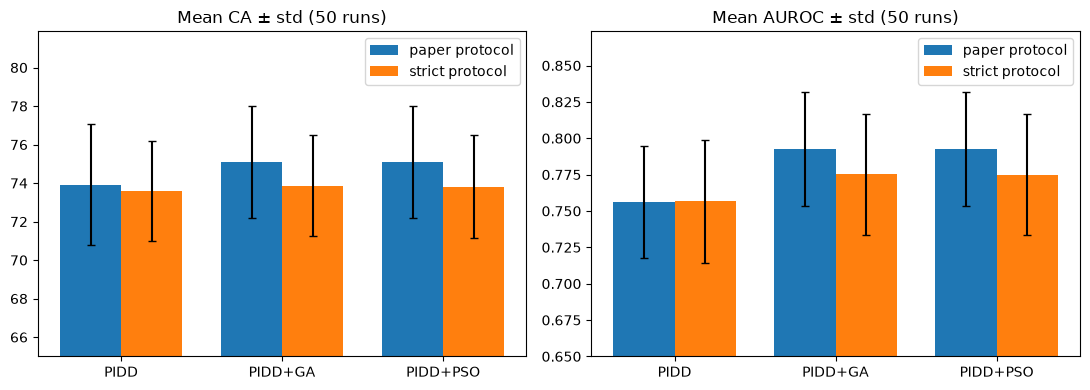

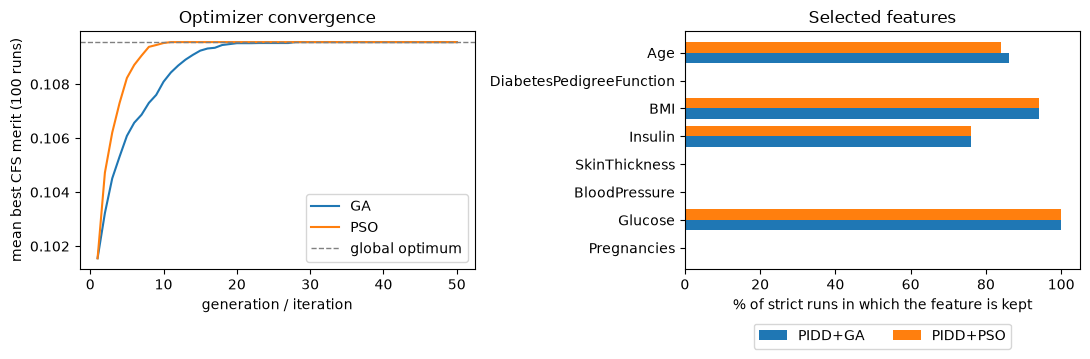

In [11]:
conv = convergence_study(apply_preprocess(raw_X, fit_preprocess(raw_X)).to_numpy(), y)
report(df, g_ga, g_pso, conv, strict_optimum_check(raw_X, y))

## 10. Reading the results
* **The paper's PIDD and PIDD+GA results reproduce.** With the paper's rule (mean of the best 5 of 10 runs per split) the `strict` protocol gives 75.52% (PIDD) and 75.76% (PIDD+GA) against 75.80% and 76.30% in the paper.
* **Realistic accuracy is about 74%** averaged over all runs; the paper's 79.55% is a best-of-10 figure.
* **The `paper` protocol is more optimistic** (77.32% for PIDD+GA) because features, medians and fences are chosen using the test patients too.
* **PSO equals GA in performance and converges faster** (median 5 vs 8 iterations); both find the same optimal subset, so accuracy cannot differ on 8 features.
* **Feature selection mainly shrinks the tree** (about 17.8 → 9.7 leaves); under `strict` AUROC improves by about 0.019, accuracy does not significantly.

See `REPORT_PIDD_GA_PSO.md` for the full discussion and limitations.